# Multi-teacher distillation on the 2-D toy: a walkthrough

This notebook walks through one multi-teacher distillation (MTD) update on the toy problem, piece by piece, and then
runs 300 updates. Every piece of the method is a call into the shared code (`distillation/flow_utils.py`,
`dmd_loss.py`, `router.py`, `step.py`) or the toy code (`distillation/toy/`); the notebook re-implements none of it.

**The toy.** Two tasks, each with an exact Gaussian-mixture teacher over a 2-step, 2-D action chunk: task 1 has
2 modes, task 2 has 3, all with σ = 0.15 and equal weights. Actions have GR00T's shape `[B, H, D] = [B, 2, 3]`;
dimension 2 is padding and is masked out of every loss and norm. An observation o ∈ [−1, 1] shifts all modes of a
task together. Plots show step-1 coordinates (step 2 is step 1 plus a fixed offset, so it carries no extra
information).

**Two time conventions.**
- *Paper convention* (all method math): τ = 1 is pure noise, A^τ = (1 − τ)·A + τ·ε, velocity target ε − A.
- *Native GR00T convention* (all models): t = 0 is pure noise, t = 1 the clean action, velocity target A − ε.
- τ = 1 − t and v_paper = −v_native. `flow_utils` is the only place that converts.

**One update**, for a sample of task k with teacher T_k, student v_θ and fake network v_ψ:
1. student sample A^S = FlowSolve(v_θ; z, N = 4), keeping gradients;
2. fake network: K_ψ flow-matching steps on the detached A^S (so v_ψ tracks the *student's* distribution);
3. DMD: noise A^S to A^τ, compare v_ψ and v_{T_k} there, g = −(1 − τ)·(v_ψ − v_T)/‖v_ψ − v_T‖, push A^S along −g;
4. FM: teacher samples A^T = FlowSolve(v_{T_k}; z′, N = 4), flow-matching loss of the student on them;
5. one student step on α_DMD·L_DMD + α_FM·L_FM;
6. IDA: ψ ← λ_IDA·ψ + (1 − λ_IDA)·θ.

Sections: **0** setup · **1** teacher vs. initial student · **2** one sample and its noisy version ·
**3** velocities and g at that point · **4** DMD arrows on many samples · **5** the FM term ·
**6** 300 updates · summary.

## 0. Setup

Find the project root (walk up from the working directory until a folder contains `distillation/`), put it on the
import path and make it the working directory. Hide the GPU: everything here runs on the CPU, with 4 threads.

Then load the pieces:
- the two exact teachers (`make_teachers()`), wrapped in a `TeacherRouter` that sends every sample to its own task's
  teacher;
- the pre-trained student from `distillation/toy/runs/student_init.pt`, trained by flow matching on a deliberately
  wrong *base* distribution (modes shifted up by 0.25, σ × 1.4, one task-2 mode at half weight);
- the fake network, an exact copy of the student, and a frozen copy of the initial student for comparisons later;
- the distillation settings used in Section 6: α_DMD = α_FM = 0.5, λ_IDA = 0.99, K_ψ = 1, N = 4 solver steps.

Every random draw uses an explicit `torch.Generator` with a fixed seed (one per section), so the notebook prints the
same numbers on every run. Figures drawn by `plots.py` go into a temporary folder and are shown inline; nothing is
written to `distillation/toy/figures/`.

In [1]:
import copy
import io
import os
import sys
import tempfile
import time
from pathlib import Path

os.environ["CUDA_VISIBLE_DEVICES"] = ""  # CPU only: the GPU is hidden before torch is imported

ROOT = Path.cwd().resolve()
while not (ROOT / "distillation").is_dir():
    if ROOT == ROOT.parent:
        raise RuntimeError(f"no directory containing distillation/ above {Path.cwd()}")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

import matplotlib.pyplot as plt
import torch
from IPython.display import Image, display
from matplotlib.patches import Circle
from PIL import Image as PILImage

from distillation import flow_utils
from distillation.dmd_loss import dmd_direction, flow_matching_loss
from distillation.interfaces import DistillConfig
from distillation.router import TeacherRouter
from distillation.step import distill_step, dmd_direction_at_noisy
from distillation.toy import metrics, plots, problem
from distillation.toy.gmm_teacher import make_teachers
from distillation.toy.plots import step1_coords
from distillation.toy.pretrain import CHECKPOINT, base_teachers
from distillation.toy.train_toy import load_student

torch.set_num_threads(4)
plt.rcParams.update({"figure.dpi": 72, "font.size": 9})
COLORS = {"teacher": "#2a78d6", "student": "#eb6834", "fake": "#1baf7a", "initial": "#8a8a85"}
FIG_TMP = tempfile.TemporaryDirectory(prefix="a2u_walkthrough_")  # plots.py PNGs; removed when the kernel exits
FIG_DIR = Path(FIG_TMP.name)


def rng(seed: int) -> torch.Generator:
    """A fresh CPU generator with a fixed seed."""
    return torch.Generator().manual_seed(seed)


def display_png(png: bytes, scale: float = 1.0) -> None:
    """Display a PNG shrunk for embedding: optional resize, then a 128-colour palette (keeps the notebook small)."""
    image = PILImage.open(io.BytesIO(png)).convert("RGB")
    if scale != 1.0:
        image = image.resize((round(image.width * scale), round(image.height * scale)), PILImage.LANCZOS)
    buffer = io.BytesIO()
    image.quantize(colors=128, dither=PILImage.Dither.NONE).save(buffer, "PNG", optimize=True)
    display(Image(data=buffer.getvalue()))


def show(path: Path) -> None:
    """Display a PNG written by plots.py (saved at 120 dpi; shown at about 78 dpi)."""
    display_png(path.read_bytes(), scale=0.65)


def show_fig(fig: plt.Figure) -> None:
    """Display an inline matplotlib figure at 72 dpi and close it."""
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=72, bbox_inches="tight")
    plt.close(fig)
    display_png(buffer.getvalue())


teachers = make_teachers()
router = TeacherRouter(teachers)
student = load_student(CHECKPOINT)
checkpoint_info = {key: value for key, value in torch.load(CHECKPOINT).items() if key != "state_dict"}
fake = copy.deepcopy(student)
student_init = copy.deepcopy(student).requires_grad_(False)
cfg = DistillConfig(alpha_dmd=0.5, alpha_fm=0.5, k_fake=1, lambda_ida=0.99)

print(f"python {sys.executable}")
print(f"torch {torch.__version__}, CUDA_VISIBLE_DEVICES={os.environ['CUDA_VISIBLE_DEVICES']!r}, "
      f"threads {torch.get_num_threads()}, project root {ROOT}")
print("teachers:", ", ".join(f"task {k}: {t.num_modes} modes" for k, t in teachers.items()))
print(f"student: {sum(p.numel() for p in student.parameters()):,} parameters, "
      f"pre-trained {checkpoint_info['steps']} steps on base {checkpoint_info['base']}")
print("fake == student:", all(torch.equal(p, q) for p, q in zip(fake.parameters(), student.parameters())))
print(cfg)

python /mnt1/atomic2universal/third_party/conda_envs/a2u-rl-blackwell/bin/python
torch 2.7.1+cu128, CUDA_VISIBLE_DEVICES='', threads 4, project root /mnt1/atomic2universal
teachers: task 1: 2 modes, task 2: 3 modes
student: 151,044 parameters, pre-trained 8000 steps on base {'shift': 0.25, 'shift_direction': [0.0, 1.0], 'sigma_scale': 1.4, 'half_weight_mode': 0}
fake == student: True
DistillConfig(alpha_dmd=0.5, alpha_fm=0.5, k_fake=1, lambda_ida=0.99, num_flow_steps=4, norm_eps=1e-08)


## 1. Teacher vs. initial student

Draw 1,000 samples per task at o = 0 from the exact teacher and from the initial student (4-step FlowSolve, the
same sampler GR00T uses) and scatter their step-1 coordinates. The student learned the wrong base distribution, so
its modes sit too high.

Below the figure are the numbers from `metrics.evaluate` (2,000 samples at each o ∈ {−0.8, 0, 0.8}):
- **sliced W2** to the exact teacher: a distance between the two sample clouds (lower is better);
- **coverage**: number of modes holding at least 1/(2M) of the samples;
- **success**: fraction of samples within r = 0.32 of a mode centre in step 1 (≈ 90% for the exact teacher).

Two reference rows put them in scale: the **noise floor** (exact vs. exact with independent draws, the best any
sampler can score with 2,000 samples) and the **4-step teacher** (the exact teacher sampled with only 4 Euler
steps; it is what the FM term of Section 5 learns from, and what the GR00T experts will be).

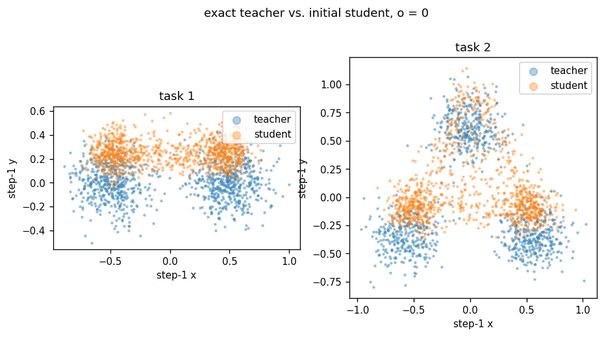

                  task  sliced W2  coverage  success
noise floor          1      0.017       2/2    90.0%
noise floor          2      0.026       3/3    90.0%
4-step teacher       1      0.084       2/2    91.8%
4-step teacher       2      0.094       3/3    85.1%
initial student      1      0.198       2/2    58.1%
initial student      2      0.158       3/3    54.1%


In [2]:
def samples_at(sample_fn, task_id: int, n: int, generator: torch.Generator, obs: float = 0.0) -> torch.Tensor:
    """n samples [n, H, D] of one task at one observation, from a metrics-style sample_fn."""
    cond = problem.make_cond(torch.full((n,), obs), torch.full((n,), task_id))
    return sample_fn(cond, n, generator)


def metrics_table(rows: dict) -> None:
    """Print {label: evaluate() result} as one line per label and task."""
    print(f"{'':18s}{'task':>4s}{'sliced W2':>11s}{'coverage':>10s}{'success':>9s}")
    for label, result in rows.items():
        for task, m in result.items():
            print(f"{label:18s}{task:>4s}{m['w2']:11.3f}{m['coverage']:>8d}/{m['num_modes']}{m['success']:9.1%}")


gen = rng(1)
exact = {k: samples_at(metrics.exact_sampler(teachers), k, 1000, gen) for k in teachers}
initial = {k: samples_at(metrics.student_sampler(student), k, 1000, gen) for k in teachers}
show(plots.plot_samples(initial, exact, "s1_initial", "exact teacher vs. initial student, o = 0", out_dir=FIG_DIR))

reference = metrics.reference_levels(teachers, gen)
metrics_initial = metrics.evaluate(metrics.student_sampler(student), teachers, gen)
metrics_table({"noise floor": reference["noise_floor"], "4-step teacher": reference["teacher_4step"],
               "initial student": metrics_initial})

## 2. One student sample and its noisy version

Take one student sample A^S of task 2 at o = 0: start from Gaussian noise z and run the student's 4-step sampler
(`flow_utils.flow_solve`, native convention, t = 0 → 1). To get a typical sample rather than a stray one between
modes, we draw 64 and keep the first that lies inside one of the student's own modes (within r of a mode centre of
the base distribution it was trained on).

DMD never compares A^S with the teacher directly. It first noises it to a paper time τ:
A^τ = (1 − τ)·A^S + τ·ε with a fresh ε ~ N(0, I) (`flow_utils.noisy_action`). Here τ = 0.5, so A^τ is half sample,
half noise; in training τ is drawn from U[0, 1) for every sample. Each row printed below is one `[H, D]` chunk; the
third entry of each step is the padding dimension: zero in A^S, but not in ε or A^τ, and masked out of everything
downstream.

The figure shows the two points in step-1 coordinates; the grey circles mark the teacher's mode centres with the
success radius r.

picked draw 0 of 64
z (start noise)   [[-1.041, 0.917, -1.304], [-1.11, -1.219, 1.168]]
A^S (sample)      [[-0.588, 0.017, -1.304], [-0.294, -0.04, 1.168]]
eps               [[-0.122, -0.476, -0.39], [0.765, 0.05, 2.256]]
A^tau, tau = 0.5  [[-0.355, -0.23, -0.847], [0.236, 0.005, 1.712]]


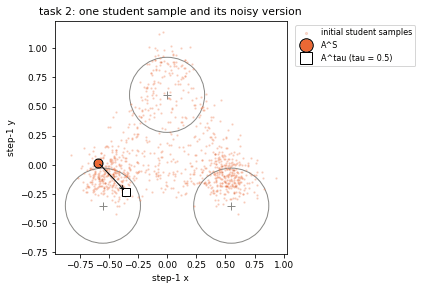

In [3]:
def draw_modes(ax, task_id: int, obs: float = 0.0) -> None:
    """Grey circles of the success radius around the teacher's step-1 mode centres at observation obs."""
    radius = metrics.SUCCESS_RADIUS * teachers[task_id].sigma
    for x, y in teachers[task_id].centers(torch.tensor([obs]))[0, :, :2].tolist():
        ax.add_patch(Circle((x, y), radius, fill=False, color=COLORS["initial"], lw=1))
        ax.plot(x, y, "+", color=COLORS["initial"], ms=8)


TASK = 2
gen = rng(2)
cond_64 = problem.make_cond(torch.zeros(64), torch.full((64,), TASK))
z_64 = torch.randn((64, problem.H, problem.D), generator=gen)
a_64 = flow_utils.flow_solve(student, z_64, cond_64, cfg.num_flow_steps, requires_grad=False)
base = base_teachers(checkpoint_info["base"]["shift"], checkpoint_info["base"]["sigma_scale"])[TASK]
dist_to_base, _ = metrics.nearest_step1(problem.to_real(a_64), base.centers(torch.zeros(1))[0])
pick = int(torch.nonzero(dist_to_base <= metrics.SUCCESS_RADIUS * teachers[TASK].sigma)[0])
z, a_student = z_64[pick:pick + 1], a_64[pick:pick + 1]

cond_one, mask_one = problem.make_cond(torch.zeros(1), torch.full((1,), TASK)), problem.action_mask(1)
eps = torch.randn(mask_one.shape, generator=gen)
tau = torch.tensor([0.5])
a_tau = flow_utils.noisy_action(a_student, eps, tau)
print(f"picked draw {pick} of 64")
for name, x in {"z (start noise)": z, "A^S (sample)": a_student, "eps": eps, "A^tau, tau = 0.5": a_tau}.items():
    print(f"{name:17s}", [[round(v, 3) for v in row] for row in x[0].tolist()])

fig, ax = plt.subplots(figsize=(6.4, 4.2))
draw_modes(ax, TASK)
ax.scatter(*step1_coords(initial[TASK]).T, s=2, alpha=0.2, color=COLORS["student"], label="initial student samples")
ax.plot(*step1_coords(a_student)[0], "o", color=COLORS["student"], mec="black", ms=9, label="A^S")
ax.plot(*step1_coords(a_tau)[0], "s", color="white", mec="black", ms=8, label="A^tau (tau = 0.5)")
ax.annotate("", step1_coords(a_tau)[0].tolist(), step1_coords(a_student)[0].tolist(),
            arrowprops={"arrowstyle": "->", "lw": 1})
ax.set(title="task 2: one student sample and its noisy version", xlabel="step-1 x", ylabel="step-1 y", aspect="equal")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0), fontsize=8, markerscale=1.5)
show_fig(fig)

## 3. Teacher and fake velocities at A^τ, and the DMD direction g

At (A^τ, τ) we ask two networks for their paper-convention velocity, each an estimate of ε − A:
- the teacher of task 2, through the router: `router.velocity_paper(a_tau, tau, cond, task_ids)`;
- the fake network: `flow_utils.velocity_paper(fake, a_tau, tau, cond)`. The adapter calls the model's native
  `velocity` at t = 1 − τ and flips the sign.

`dmd_direction` turns their difference into g = −(1 − τ)·(v_ψ − v_T)/(‖v_ψ − v_T‖ + 10⁻⁸). Only the *direction* of
the difference survives, scaled by 1 − τ, so ‖g‖ = 1 − τ = 0.5 on the real entries and g = 0 in the padding. The
student's update moves A^S along −g (the surrogate loss has gradient g/B with respect to A^S, and a descent step
goes the other way).

How to read the arrows: from a noisy point, each velocity implies a guess of the clean action, Â = A^τ − τ·v (for
the exact teacher this is the posterior mean E[A | A^τ]). Then −g points along Â_T − Â_ψ: from where the fake
network would denoise A^τ toward where the teacher would. The fake network is still an exact copy of the student,
so here this is "the teacher's guess minus the student's own guess". Â is drawn only for this picture; it is not
part of the method.

g depends on the particular ε. The dashed arrow repeats the same three calls for 2,048 fresh ε at the same A^S and
τ = 0.5 and averages: that is the push this sample gets on average at this noise level.

real entries: [step1_x, step1_y, step2_x, step2_y]
v_T (teacher)         [-0.444, -0.176, 0.098, -0.02]
v_psi (fake)          [-0.386, -0.401, 0.139, -0.236]
v_psi - v_T           [0.058, -0.226, 0.04, -0.216]
g                     [-0.091, 0.353, -0.063, 0.337]
-g (update)           [0.091, -0.353, 0.063, -0.337]
-g, mean of 2048 eps  [0.096, -0.256, 0.115, -0.219]
||v_psi - v_T|| = 0.3204, ||g|| = 0.5000 (= 1 - tau), padding entries of g: [0.0, 0.0]


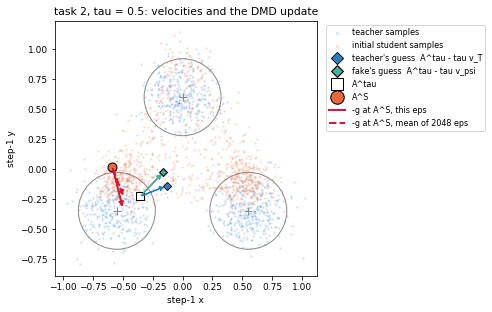

In [4]:
def real(x: torch.Tensor) -> list[float]:
    """The 4 real entries of the first chunk, rounded."""
    return [round(v, 3) for v in problem.to_real(x)[0].tolist()]


v_teacher = router.velocity_paper(a_tau, tau, cond_one, torch.full((1,), TASK))
with torch.no_grad():
    v_fake = flow_utils.velocity_paper(fake, a_tau, tau, cond_one)
g = dmd_direction(v_fake, v_teacher, tau, mask_one, cfg.norm_eps)

n_eps, gen = 2048, rng(3)
cond_rep = problem.make_cond(torch.zeros(n_eps), torch.full((n_eps,), TASK))
mask_rep, tau_rep = problem.action_mask(n_eps), tau.expand(n_eps)
eps_rep = torch.randn(mask_rep.shape, generator=gen)
a_tau_rep = flow_utils.noisy_action(a_student.expand(n_eps, -1, -1), eps_rep, tau_rep)
v_teacher_rep = router.velocity_paper(a_tau_rep, tau_rep, cond_rep, cond_rep["task"])
with torch.no_grad():
    v_fake_rep = flow_utils.velocity_paper(fake, a_tau_rep, tau_rep, cond_rep)
g_mean_eps = dmd_direction(v_fake_rep, v_teacher_rep, tau_rep, mask_rep, cfg.norm_eps).mean(dim=0, keepdim=True)

print("real entries: [step1_x, step1_y, step2_x, step2_y]")
for name, x in {"v_T (teacher)": v_teacher, "v_psi (fake)": v_fake, "v_psi - v_T": v_fake - v_teacher,
                "g": g, "-g (update)": -g, f"-g, mean of {n_eps} eps": -g_mean_eps}.items():
    print(f"{name:22s}{real(x)}")
print(f"||v_psi - v_T|| = {flow_utils.masked_norm(v_fake - v_teacher, mask_one).item():.4f}, "
      f"||g|| = {flow_utils.masked_norm(g, mask_one).item():.4f} (= 1 - tau), "
      f"padding entries of g: {g[0, :, 2].tolist()}")

t = tau.item()
guess_teacher, guess_fake = a_tau - t * v_teacher, a_tau - t * v_fake
fig, ax = plt.subplots(figsize=(7.2, 4.6))
draw_modes(ax, TASK)
ax.scatter(*step1_coords(exact[TASK]).T, s=2, alpha=0.15, color=COLORS["teacher"], label="teacher samples")
ax.scatter(*step1_coords(initial[TASK]).T, s=2, alpha=0.15, color=COLORS["student"], label="initial student samples")
for target, color, label in ((guess_teacher, COLORS["teacher"], "teacher's guess  A^tau - tau v_T"),
                             (guess_fake, COLORS["fake"], "fake's guess  A^tau - tau v_psi")):
    ax.annotate("", step1_coords(target)[0].tolist(), step1_coords(a_tau)[0].tolist(),
                arrowprops={"arrowstyle": "->", "color": color, "lw": 1.6})
    ax.plot(*step1_coords(target)[0], "D", color=color, mec="black", ms=6, label=label)
ax.plot(*step1_coords(a_tau)[0], "s", color="white", mec="black", ms=8, label="A^tau")
ax.plot(*step1_coords(a_student)[0], "o", color=COLORS["student"], mec="black", ms=9, label="A^S")
for g_k, style, label in ((g, "-", "-g at A^S, this eps"), (g_mean_eps, "--", f"-g at A^S, mean of {n_eps} eps")):
    ax.annotate("", (step1_coords(a_student) - step1_coords(g_k))[0].tolist(), step1_coords(a_student)[0].tolist(),
                arrowprops={"arrowstyle": "-|>", "color": "crimson", "lw": 2, "ls": style})
    ax.plot([], [], color="crimson", ls=style, lw=2, label=label)
ax.set(title="task 2, tau = 0.5: velocities and the DMD update", xlabel="step-1 x", ylabel="step-1 y", aspect="equal")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0), fontsize=8, markerscale=1.5)
show_fig(fig)

## 4. DMD arrows over many student samples

Now the same computation on 200 student samples per task (o = 0), using the step-(3) helper of `distill_step`
itself (`step.dmd_direction_at_noisy`: fresh τ ~ U[0, 1) and ε, A^τ, teacher velocity via the router, fake velocity,
`dmd_direction`), so the arrows are exactly what training uses.

One draw of (τ, ε) gives a noisy direction, as Section 3 showed. Training averages over a batch of 512 and many
steps, so here every sample gets 32 independent draws and we average its g. The red arrows show the averaged −g,
the direction a descent step moves each sample; the blue dots are exact teacher samples. The arrows should point
from the student's too-high modes toward the teacher's modes. Because each draw of g has norm 1 − τ, the length of
an averaged arrow measures how consistently the draws agree, not how far the sample is from the teacher.

With the fake network equal to the student, g measures how the student's distribution differs from the teacher's:
v_ψ is the student's own velocity field. (Strictly, the fake network describes the distribution the student was
trained on, not exactly the one its 4-step sampler produces; from Section 6 on, the fake network is trained on the
actual samples.)

The check below the figure is the cosine between −g and the vector from each sample to its nearest teacher mode
centre (4-D): the fraction with cosine > 0 and the mean, for single draws and for the 32-draw average.

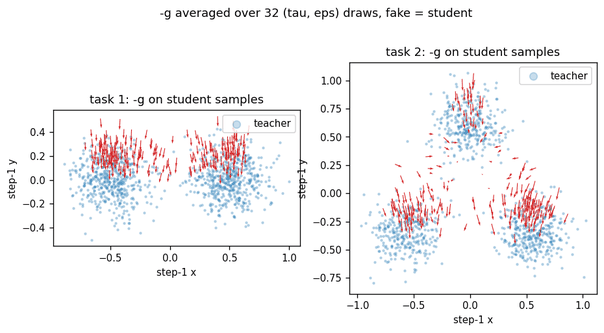

task 1, single draw  : cos(-g, toward nearest mode) > 0 for 99%, mean +0.81; mean step-1 -g = [0.002, -0.308]
task 1, 32-draw mean : cos(-g, toward nearest mode) > 0 for 100%, mean +0.85; mean step-1 -g = [-0.001, -0.342]
task 2, single draw  : cos(-g, toward nearest mode) > 0 for 87%, mean +0.63; mean step-1 -g = [-0.009, -0.237]
task 2, 32-draw mean : cos(-g, toward nearest mode) > 0 for 97%, mean +0.77; mean step-1 -g = [-0.004, -0.237]


In [5]:
def toward_nearest_mode(a: torch.Tensor, task_id: int) -> torch.Tensor:
    """Vector [N, 4] from each sample to its nearest teacher mode centre at o = 0 (step-1 distance)."""
    x = problem.to_real(a).double()
    centers = teachers[task_id].centers(torch.zeros(1))[0]
    _, nearest = metrics.nearest_step1(x, centers)
    return centers[nearest] - x


N_SAMPLES, N_DRAWS = 200, 32
gen = rng(4)
a_many, g_mean, g_single = {}, {}, {}
for k in teachers:
    a_many[k] = samples_at(metrics.student_sampler(student), k, N_SAMPLES, gen)
    reps = N_SAMPLES * N_DRAWS
    cond = problem.make_cond(torch.zeros(reps), torch.full((reps,), k))
    g_all, _ = dmd_direction_at_noisy(fake, router, a_many[k].repeat_interleave(N_DRAWS, dim=0), cond,
                                      cond["task"], problem.action_mask(reps), cfg.norm_eps, gen)
    g_all = g_all.view(N_SAMPLES, N_DRAWS, problem.H, problem.D)
    g_mean[k], g_single[k] = g_all.mean(dim=1), g_all[:, 0]

show(plots.plot_dmd_arrows(a_many, g_mean, exact, "s4_arrows",
                           f"-g averaged over {N_DRAWS} (tau, eps) draws, fake = student", out_dir=FIG_DIR))
for k in teachers:
    to_mode = toward_nearest_mode(a_many[k], k)
    for label, g_k in (("single draw", g_single[k]), (f"{N_DRAWS}-draw mean", g_mean[k])):
        cos = torch.cosine_similarity(-problem.to_real(g_k).double(), to_mode, dim=1)
        mean_step = [round(v, 3) for v in (-step1_coords(g_k)).mean(0).tolist()]
        print(f"task {k}, {label:13s}: cos(-g, toward nearest mode) > 0 for {(cos > 0).double().mean():.0%}, "
              f"mean {cos.mean():+.2f}; mean step-1 -g = {mean_step}")

## 5. The FM term: teacher-generated targets

The second half of the student's objective is plain flow matching on teacher samples. `router.flow_solve` draws
A^T = FlowSolve(v_{T_k}; z′, N = 4) from each sample's own teacher, without gradients: exactly what a 4-step GR00T
expert produces, discretization error included (the "4-step teacher" row of Section 1). The figure compares these
targets with exact teacher samples: the 4-step modes are visibly too narrow, and a thin bridge of samples joins them.

`flow_matching_loss(student, A^T, cond, mask, generator)` then noises A^T at a random τ and regresses the student's
paper velocity on ε − A^T, over the real entries only. Unlike DMD, the FM gradient does not pass through the student's
sampler: it trains the velocity field directly, at all noise levels, toward the 4-step teacher's samples. So DMD pulls
toward the teacher's velocity field (here the exact mixture), and FM toward what the 4-step teacher actually outputs.

The FM loss is never zero, because ε − A is not determined by A^τ. To give the student's loss a scale, the table also
shows the loss of the exact teacher on the same targets (close to the irreducible part) and the student's loss on
its own samples (what it was trained to fit). All three use the same seed, so they see the same τ and ε.

task  student on A^T  teacher on A^T  student on A^S
1             0.4827          0.3407          0.3881
2             0.5489          0.4593          0.4837


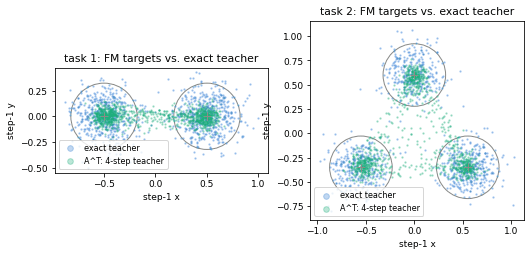

In [6]:
gen = rng(5)
n = 4096
a_teacher_targets = {}
print(f"{'task':4s}{'student on A^T':>16s}{'teacher on A^T':>16s}{'student on A^S':>16s}")
for k in teachers:
    cond = problem.make_cond(torch.zeros(n), torch.full((n,), k))
    mask = problem.action_mask(n)
    a_teacher = router.flow_solve(torch.randn(mask.shape, generator=gen), cond, cond["task"], cfg.num_flow_steps)
    a_own = flow_utils.flow_solve(student, torch.randn(mask.shape, generator=gen), cond, cfg.num_flow_steps,
                                  requires_grad=False)
    with torch.no_grad():
        losses = [flow_matching_loss(model, a_clean, cond, mask, rng(50)).item()
                  for model, a_clean in ((student, a_teacher), (teachers[k], a_teacher), (student, a_own))]
    print(f"{k:<4d}" + "".join(f"{v:16.4f}" for v in losses))
    a_teacher_targets[k] = a_teacher[:1000]

fig, axes = plt.subplots(1, 2, figsize=(8.4, 4.0))
for ax, k in zip(axes, teachers):
    draw_modes(ax, k)
    ax.scatter(*step1_coords(exact[k]).T, s=2, alpha=0.3, color=COLORS["teacher"], label="exact teacher")
    ax.scatter(*step1_coords(a_teacher_targets[k]).T, s=2, alpha=0.3, color=COLORS["fake"], label="A^T: 4-step teacher")
    ax.set(title=f"task {k}: FM targets vs. exact teacher", xlabel="step-1 x", ylabel="step-1 y", aspect="equal")
    ax.legend(loc="lower left", fontsize=8, markerscale=4)
show_fig(fig)

## 6a. 300 updates of `distill_step`

Now the full update, 300 times: `distill_step(student, fake, router, batch, cfg, opt_student, opt_fake, generator)`
with α_DMD = α_FM = 0.5, λ_IDA = 0.99, K_ψ = 1, batches of 512 (tasks mixed 50/50, o ~ U[−1, 1]) and Adam with
lr 10⁻⁴ for both networks: the settings of the EXPERIMENT runs, for a tenth of their 3,000 updates.

The loop records, with generators separate from the training one (so recording does not change the training run):
- every update: the metrics `distill_step` returns (both losses, the fake loss, mean ‖v_ψ − v_T‖, gradient norm);
- every 5 updates: where the student's and the fake network's samples sit, as the mean step-1 offset from the
  nearest teacher mode centre (o = 0, 4-step samples from one fixed set of 2,000 noises per task);
- every 25 updates: `metrics.evaluate` of the student, and how closely the fake network tracks the current student
  (Section 6e);
- at 0/100/200/300 updates: student and fake samples from the fixed noises, for the snapshots.

In [7]:
STEPS, BATCH, SNAPSHOTS, OFFSET_EVERY, EVAL_EVERY, N_FIXED = 300, 512, (0, 100, 200, 300), 5, 25, 2000
gen, eval_gen, fixed_gen = rng(6), rng(60), rng(61)
opt_student = torch.optim.Adam(student.parameters(), lr=1e-4)
opt_fake = torch.optim.Adam(fake.parameters(), lr=1e-4)
log = {"config": {"run": "DMD + FM, 300 updates (notebook)", "alpha_dmd": cfg.alpha_dmd, "alpha_fm": cfg.alpha_fm,
                  "lambda_ida": cfg.lambda_ida, "k_fake": cfg.k_fake, "steps": STEPS, "batch_size": BATCH, "lr": 1e-4},
       "train": [], "eval": [], "reference": reference}
fixed_z = {k: torch.randn((N_FIXED, problem.H, problem.D), generator=fixed_gen) for k in teachers}
fixed_cond = {k: problem.make_cond(torch.zeros(N_FIXED), torch.full((N_FIXED,), k)) for k in teachers}
offsets, tracking, snapshots = [], [], {}


def fixed_noise_samples(model, task_id: int) -> torch.Tensor:
    """4-step samples of a model for one task at o = 0 from the fixed noises (the same points at every update)."""
    return flow_utils.flow_solve(model, fixed_z[task_id], fixed_cond[task_id], cfg.num_flow_steps, requires_grad=False)


def mean_offset(a: torch.Tensor, task_id: int) -> list[float]:
    """Mean step-1 offset [x, y] of samples from their nearest teacher mode centre."""
    return (-toward_nearest_mode(a, task_id)[:, :2]).mean(dim=0).tolist()


def tracking_row(step: int) -> dict:
    """Sliced W2 to fresh student samples and flow-matching loss on them, for the fake and the frozen initial student."""
    row = {"step": step}
    for k in teachers:
        a_now = samples_at(metrics.student_sampler(student), k, N_FIXED, eval_gen)
        for name, model in (("fake", fake), ("initial", student_init)):
            a_other = samples_at(metrics.student_sampler(model), k, N_FIXED, eval_gen)
            row[f"w2_{name}_{k}"] = metrics.sliced_w2(problem.to_real(a_other), problem.to_real(a_now), eval_gen)
            with torch.no_grad():
                row[f"fm_{name}_{k}"] = flow_matching_loss(model, a_now, fixed_cond[k], problem.action_mask(N_FIXED),
                                                           rng(50)).item()
    return row


def record(step: int) -> None:
    """Offsets every OFFSET_EVERY updates, evaluation and tracking every EVAL_EVERY, snapshots at SNAPSHOTS."""
    samples = {(name, k): fixed_noise_samples(m, k) for name, m in (("student", student), ("fake", fake))
               for k in teachers} if step % OFFSET_EVERY == 0 or step in SNAPSHOTS else {}
    if step % OFFSET_EVERY == 0:
        offsets.append({"step": step, **{f"{name}_{k}": mean_offset(a, k) for (name, k), a in samples.items()}})
    if step % EVAL_EVERY == 0:
        log["eval"].append({"step": step,
                            "metrics": metrics.evaluate(metrics.student_sampler(student), teachers, eval_gen)})
        tracking.append(tracking_row(step))
    if step in SNAPSHOTS:
        snapshots[step] = samples


start = time.time()
record(0)
for step in range(1, STEPS + 1):
    row = distill_step(student, fake, router, problem.sample_batch(BATCH, gen), cfg, opt_student, opt_fake, gen)
    log["train"].append({"step": step, **row})
    record(step)
    if step % 50 == 0:
        print(f"update {step:3d} ({time.time() - start:4.1f} s): " + ", ".join(f"{k} {v:.3f}" for k, v in row.items()))

update  50 ( 2.6 s): loss_dmd 0.158, loss_fake 0.395, vdiff_norm 0.357, loss_fm 0.381, grad_norm 0.376


update 100 ( 4.8 s): loss_dmd 0.173, loss_fake 0.485, vdiff_norm 0.497, loss_fm 0.395, grad_norm 0.441


update 150 ( 6.9 s): loss_dmd 0.168, loss_fake 0.483, vdiff_norm 0.383, loss_fm 0.411, grad_norm 0.665


update 200 ( 9.1 s): loss_dmd 0.165, loss_fake 0.469, vdiff_norm 0.452, loss_fm 0.381, grad_norm 0.503


update 250 (11.2 s): loss_dmd 0.176, loss_fake 0.506, vdiff_norm 0.329, loss_fm 0.414, grad_norm 0.514


update 300 (13.4 s): loss_dmd 0.164, loss_fake 0.435, vdiff_norm 0.342, loss_fm 0.406, grad_norm 0.480


## 6b. Snapshots

Student (orange) and fake-network (green) samples from the same 600 noises per task, at 0, 100, 200 and 300 updates.
Grey circles: the teacher's modes with the success radius. At update 0 the two clouds coincide (the fake network is
a copy of the student; the overlap looks brown). Within 100 updates the student has left its too-high position and
moved into the circles, but it does not come to rest: at update 100 it sits below the centres with the fake network
above them, at 200 it is on the centres with the fake network below, and at 300 it is lower-left of them with the
fake network upper-right. Section 6d shows what is going on.

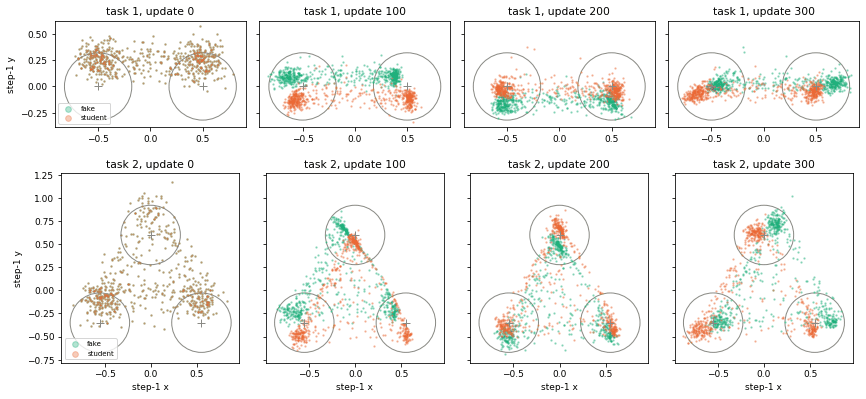

In [8]:
fig, axes = plt.subplots(2, len(SNAPSHOTS), figsize=(3.0 * len(SNAPSHOTS), 6.0), sharex="row", sharey="row")
for row, k in enumerate(teachers):
    for col, step in enumerate(SNAPSHOTS):
        ax = axes[row, col]
        draw_modes(ax, k)
        for name in ("fake", "student"):
            ax.scatter(*step1_coords(snapshots[step][name, k][:600]).T, s=2, alpha=0.35, color=COLORS[name], label=name)
        ax.set(title=f"task {k}, update {step}", aspect="equal")
        if col == 0:
            ax.set_ylabel("step-1 y")
            ax.legend(loc="lower left", fontsize=7, markerscale=4)
        if row == 1:
            ax.set_xlabel("step-1 x")
fig.tight_layout()
show_fig(fig)

## 6c. Loss and metric curves

First figure (`plots.plot_loss_curves`): the per-update values `distill_step` returned. `loss_dmd` is the surrogate
(1/2B)·Σ‖g‖², which by construction is the batch mean of (1 − τ)²/2 ≈ 1/6 whatever the student does, so it says
nothing about progress. `loss_fm` and `vdiff_norm` (mean ‖v_ψ − v_T‖ over the batch) do: both drop quickly, and
`vdiff_norm` then oscillates instead of settling. Second figure (`plots.plot_metric_curves`):
sliced W2, coverage and success of the student every 25 updates, with the noise floor (dotted) and the 4-step
teacher (dashed); the 25-update spacing samples that oscillation only coarsely.

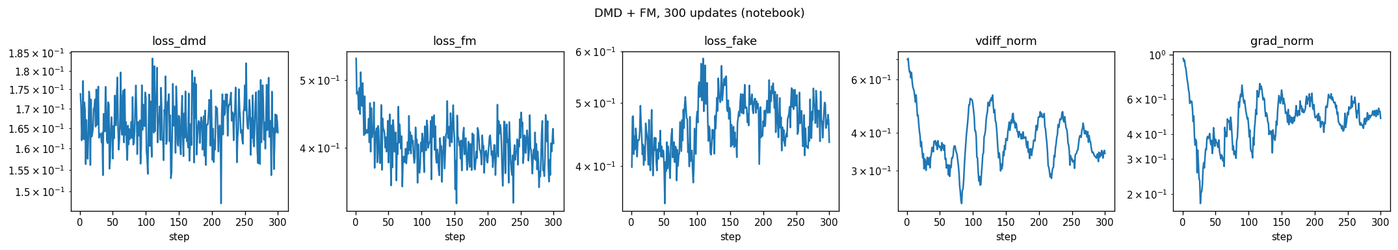

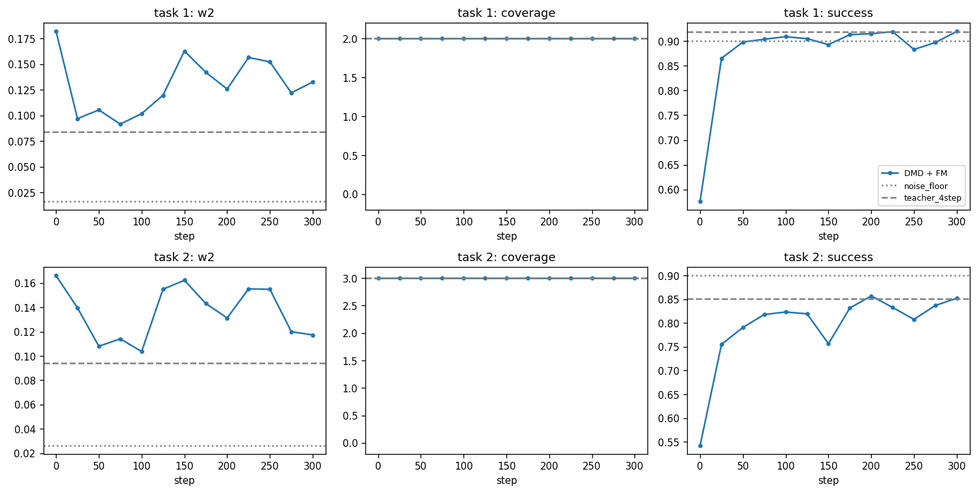

In [9]:
show(plots.plot_loss_curves(log, "s6_losses", out_dir=FIG_DIR))
show(plots.plot_metric_curves({"DMD + FM": log}, "s6_metrics", out_dir=FIG_DIR))

## 6d. The fake network follows the student, a step behind

The fake network's job is to describe the *current* student, so that v_ψ − v_T measures what is still wrong with it.
The figure plots, every 5 updates, the mean step-1 offset of the student's and the fake network's samples from the
nearest teacher mode centre (y in the top row, x in the bottom row; 0 = on the teacher's centre). The student starts
0.25 too high (task 2: less, because of its half-weight mode), crosses the target within about 25 updates and then
keeps circling it, in x as well as in y, one cycle every 50–70 updates; both tasks move together, because one network
serves both. The fake network traces the same curve a few updates later: the printed delay is the shift of the fake
network's curve that best matches the student's (from update 50 on).

That delay is the reason for the circling. The update direction −g compares the teacher with the fake network, i.e.
with where the student *was*, and because g is normalized its strength does not shrink as the student gets close:
the push continues past the target until the fake network catches up, and then reverses.

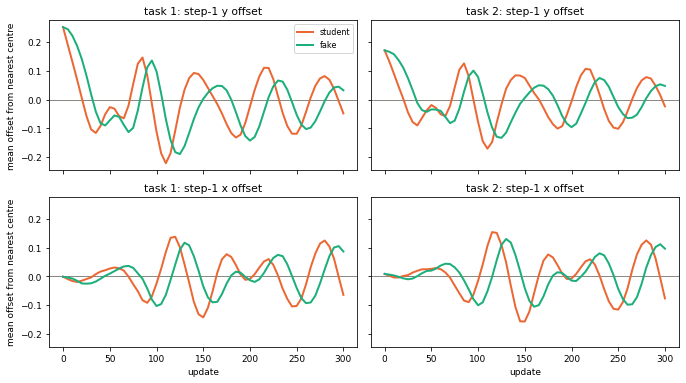

update    student 1 (x, y)       fake 1 (x, y)    student 2 (x, y)       fake 2 (x, y)
     0    (-0.001, +0.252)    (-0.001, +0.252)    (+0.008, +0.171)    (+0.008, +0.171)
    50    (+0.027, -0.026)    (+0.010, -0.072)    (+0.026, -0.019)    (+0.020, -0.034)
   100    (-0.025, -0.112)    (-0.103, +0.098)    (-0.015, -0.078)    (-0.100, +0.078)
   150    (-0.143, +0.068)    (-0.035, +0.002)    (-0.157, +0.075)    (-0.041, +0.006)
   200    (-0.009, -0.024)    (-0.013, -0.143)    (-0.008, -0.007)    (-0.015, -0.096)
   250    (-0.103, -0.119)    (-0.040, -0.053)    (-0.116, -0.102)    (-0.044, -0.026)
   300    (-0.064, -0.048)    (+0.086, +0.032)    (-0.077, -0.024)    (+0.096, +0.048)
task 1: fake network trails the student by ~15 updates (correlation 0.93 at that delay, 0.17 without delay)
task 2: fake network trails the student by ~15 updates (correlation 0.93 at that delay, 0.17 without delay)


In [10]:
steps_o = [r["step"] for r in offsets]
fig, axes = plt.subplots(2, 2, figsize=(9.6, 5.4), sharex=True, sharey=True)
for col, k in enumerate(teachers):
    for row, (axis, axis_name) in enumerate(((1, "y"), (0, "x"))):
        ax = axes[row, col]
        ax.axhline(0.0, color=COLORS["initial"], lw=1)
        for name in ("student", "fake"):
            ax.plot(steps_o, [r[f"{name}_{k}"][axis] for r in offsets], color=COLORS[name], lw=2, label=name)
        ax.set(title=f"task {k}: step-1 {axis_name} offset")
        if row == 1:
            ax.set_xlabel("update")
        if col == 0:
            ax.set_ylabel("mean offset from nearest centre")
axes[0, 0].legend(fontsize=8)
fig.tight_layout()
show_fig(fig)
print(f"{'update':>6s}" + "".join(f"{f'{name} {k} (x, y)':>20s}" for k in teachers for name in ("student", "fake")))
for r in offsets[::10]:
    print(f"{r['step']:6d}" + "".join(f"{'({:+.3f}, {:+.3f})'.format(*r[f'{name}_{k}']):>20s}"
                                      for k in teachers for name in ("student", "fake")))


def best_delay(task_id: int, first_step: int = 50, max_shift: int = 12) -> tuple[int, float, float]:
    """Delay (updates) of the fake's offset curve that best matches the student's; correlation there and at 0."""
    rows = [r for r in offsets if r["step"] >= first_step]
    lead = torch.tensor([r[f"student_{task_id}"] for r in rows])
    follow = torch.tensor([r[f"fake_{task_id}"] for r in rows])
    corr = [torch.corrcoef(torch.stack([lead[:len(rows) - s].flatten(), follow[s:].flatten()]))[0, 1].item()
            for s in range(max_shift + 1)]
    best = max(range(len(corr)), key=corr.__getitem__)
    return best * OFFSET_EVERY, corr[best], corr[0]


for k in teachers:
    delay, corr_best, corr_0 = best_delay(k)
    print(f"task {k}: fake network trails the student by ~{delay} updates "
          f"(correlation {corr_best:.2f} at that delay, {corr_0:.2f} without delay)")

## 6e. How closely does the fake network track the student?

Two measures every 25 updates, each computed on 2,000 fresh samples of the *current* student per task (o = 0), for the
fake network and, as the "no tracking" baseline, for the frozen initial student (which is what the fake network
would be without its updates and IDA):
- **sliced W2** between that network's 4-step samples and the student's samples;
- **flow-matching loss** of that network on the student's samples: the loss the fake network is trained on, lower
  means a better description of the student's current distribution (same seed for both, so the same τ and ε).

The dotted line is the W2 two independent draws of the same distribution give (the exact teacher at o = 0).

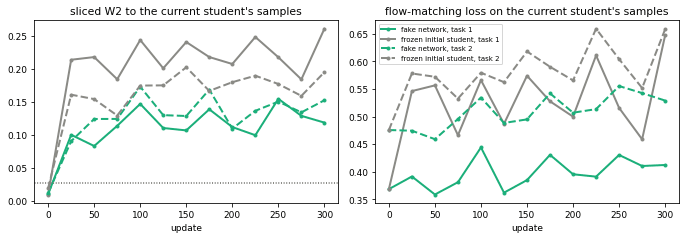

task 1, mean over updates 100-300: sliced W2 fake 0.124 vs. frozen 0.225; FM loss fake 0.407 vs. frozen 0.543
task 2, mean over updates 100-300: sliced W2 fake 0.143 vs. frozen 0.180; FM loss fake 0.523 vs. frozen 0.599


In [11]:
floor_w2 = {k: metrics.sliced_w2(*(problem.to_real(samples_at(metrics.exact_sampler(teachers), k, N_FIXED, eval_gen))
                                   for _ in range(2)), eval_gen) for k in teachers}
steps_t = [r["step"] for r in tracking]
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.4))
for k, style in zip(teachers, ("-", "--")):
    for name, label in (("fake", "fake network"), ("initial", "frozen initial student")):
        color = COLORS["fake" if name == "fake" else "initial"]
        axes[0].plot(steps_t, [r[f"w2_{name}_{k}"] for r in tracking], ls=style, marker=".", color=color, lw=2,
                     label=f"{label}, task {k}")
        axes[1].plot(steps_t, [r[f"fm_{name}_{k}"] for r in tracking], ls=style, marker=".", color=color, lw=2,
                     label=f"{label}, task {k}")
    axes[0].axhline(floor_w2[k], color=COLORS["initial"], ls=":", lw=1)
axes[0].set(title="sliced W2 to the current student's samples", xlabel="update")
axes[1].set(title="flow-matching loss on the current student's samples", xlabel="update")
axes[1].legend(fontsize=7)
fig.tight_layout()
show_fig(fig)


def late_mean(key: str) -> float:
    """Mean of a tracking quantity over updates 100-300."""
    late = [r[key] for r in tracking if r["step"] >= 100]
    return sum(late) / len(late)


for k in teachers:
    print(f"task {k}, mean over updates 100-300: sliced W2 fake {late_mean(f'w2_fake_{k}'):.3f} vs. frozen "
          f"{late_mean(f'w2_initial_{k}'):.3f}; FM loss fake {late_mean(f'fm_fake_{k}'):.3f} vs. frozen "
          f"{late_mean(f'fm_initial_{k}'):.3f}")

## 6f. What 300 updates did

The table compares the student before and after the 300 updates with the 4-step teacher, and gives the relative W2
reduction (the EXPERIMENT runs target ≥ 80% after 3,000 updates). Below it, a closer look at *where* the samples
are: for each task, the mean offset and the standard deviation of step-1 samples from their nearest teacher mode
centre (o = 0, 4,000 samples) for the exact teacher, the 4-step teacher, the initial student, the student after 300
updates and the fake network. The exact teacher has offset ≈ 0 and std ≈ σ = 0.15 on both axes.

In [12]:
def offset_and_spread(a: torch.Tensor, task_id: int) -> str:
    """Mean step-1 offset (x, y) and per-axis std of samples from their nearest teacher mode centre."""
    resid = -toward_nearest_mode(a, task_id)[:, :2]
    (mx, my), (sx, sy) = resid.mean(0).tolist(), resid.std(0).tolist()
    return f"offset ({mx:+.3f}, {my:+.3f})   std ({sx:.3f}, {sy:.3f})"


metrics_final = log["eval"][-1]["metrics"]
metrics_table({"4-step teacher": reference["teacher_4step"], "initial student": metrics_initial,
               f"after {STEPS} updates": metrics_final})
for k in ("1", "2"):
    w0, w1, wt = metrics_initial[k]["w2"], metrics_final[k]["w2"], reference["teacher_4step"][k]["w2"]
    best = min(log["eval"], key=lambda e: e["metrics"][k]["w2"])
    print(f"task {k}: W2 {w0:.3f} -> {w1:.3f} ({1 - w1 / w0:.0%} lower; lowest {best['metrics'][k]['w2']:.3f} "
          f"at update {best['step']}; 4-step teacher {wt:.3f}); success {metrics_initial[k]['success']:.1%} -> "
          f"{metrics_final[k]['success']:.1%}")
print()
gen = rng(7)
for k in teachers:
    print(f"task {k}")
    for label, sample_fn in (("exact teacher", metrics.exact_sampler(teachers)),
                             ("4-step teacher", metrics.teacher_sampler(teachers)),
                             ("initial student", metrics.student_sampler(student_init)),
                             (f"student @ {STEPS}", metrics.student_sampler(student)),
                             (f"fake @ {STEPS}", metrics.student_sampler(fake))):
        print(f"  {label:16s} {offset_and_spread(samples_at(sample_fn, k, 4000, gen), k)}")
print(f"\n{STEPS} updates took {time.time() - start:.0f} s including the recording")

                  task  sliced W2  coverage  success
4-step teacher       1      0.084       2/2    91.8%
4-step teacher       2      0.094       3/3    85.1%
initial student      1      0.198       2/2    58.1%
initial student      2      0.158       3/3    54.1%
after 300 updates    1      0.132       2/2    91.9%
after 300 updates    2      0.117       3/3    85.2%
task 1: W2 0.198 -> 0.132 (33% lower; lowest 0.092 at update 75; 4-step teacher 0.084); success 58.1% -> 91.9%
task 2: W2 0.158 -> 0.117 (26% lower; lowest 0.104 at update 100; 4-step teacher 0.094); success 54.1% -> 85.2%

task 1
  exact teacher    offset (-0.002, -0.004)   std (0.149, 0.151)
  4-step teacher   offset (+0.002, -0.001)   std (0.161, 0.058)


  initial student  offset (+0.001, +0.252)   std (0.187, 0.100)
  student @ 300    offset (-0.065, -0.047)   std (0.154, 0.059)
  fake @ 300       offset (+0.089, +0.034)   std (0.168, 0.057)
task 2
  exact teacher    offset (-0.002, -0.001)   std (0.149, 0.150)
  4-step teacher   offset (+0.001, +0.002)   std (0.146, 0.146)
  initial student  offset (+0.007, +0.177)   std (0.186, 0.220)
  student @ 300    offset (-0.074, -0.020)   std (0.139, 0.157)
  fake @ 300       offset (+0.104, +0.053)   std (0.154, 0.161)

300 updates took 16 s including the recording


## Summary

**The pieces (Sections 1–5).**
- The initial student covers every mode but sits too high (0.25 on task 1, about 0.18 on task 2): sliced W2
  0.198 / 0.158 (task 1 / task 2) against 0.084 / 0.094 for the 4-step teacher, success 58% / 54%.
- `noisy_action`, the two `velocity_paper` calls (router and adapter) and `dmd_direction` behave as specified:
  ‖g‖ = 1 − τ on the real entries and g = 0 in the padding.
- −g points toward the teacher. It has a positive cosine with the direction to the nearest teacher mode for 99% / 87%
  of single (τ, ε) draws and for 100% / 97% of 32-draw averages. A single draw is noisy; the average is what training
  sees.
- The FM targets are 4-step teacher samples, not exact ones: on task 1 they are much too narrow across the modes
  (y std 0.058 instead of σ = 0.15), and a thin bridge of samples joins the modes.

**What 300 updates do.**
- The student reaches the teacher fast: its offset is gone within about 25 updates, coverage stays complete, success
  rises to 92% / 85% (the 4-step teacher's level), and W2 is lowest around updates 75–100 (0.092 / 0.104, close to
  the 4-step teacher).
- The fake network follows the student. Its offset curve matches the student's with a delay of about 15 updates
  (correlation 0.93). Against the current student, it scores sliced W2 0.12 / 0.14 and FM loss 0.41 / 0.52, against
  0.23 / 0.18 and 0.54 / 0.60 for a frozen copy of the initial student (means over updates 100–300).

**What they do not do.**
- Converge. After 300 updates W2 is 0.132 / 0.117, only 33% / 26% below the start (the EXPERIMENT runs target ≥ 80%
  after 3,000 updates) and still above the 4-step teacher. After its first approach the student circles the target,
  in x as well as in y, with an amplitude of about 0.1–0.2 (comparable to σ), and the fake network trails it; W2 rises
  and falls with that cycle. The likely cause is visible in the method: g is normalized, so the push has the same
  strength however close the student is, and it is aimed with the fake network, which describes the student of about
  15 updates earlier. How this develops over 3,000 updates and with other λ_IDA and K_ψ is what the runs in
  `RESULTS.md` measure.
- Match the teacher's shape. On task 1 the student is as narrow across the modes as the 4-step teacher (y std 0.059
  instead of 0.15), so its success (92%) is slightly above the exact teacher's (90%) while its W2 is still above the
  4-step teacher's. Toy success alone flatters a too-narrow student; read it together with W2.